# Recipes Dataset — Extended EDA (Ratings, Votes, Prep Time, Category)

Builds on the CulinaryDB EDA. This dataset adds `Ratings`, `Votes`, `Prep_Time`, `Nutrients`, and `Category`, so before any plotting we audit missingness column-by-column instead of assuming one null-handling strategy fits all of them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Load the data

Upload your CSV via the Colab file browser (left sidebar → files icon → upload) and set `CSV_PATH` below, or use the upload widget.

In [2]:
# Option A: use Colab's upload widget (uncomment to use)
# from google.colab import files
# uploaded = files.upload()
# CSV_PATH = list(uploaded.keys())[0]

# Option B: if you've already uploaded the file, just point to it
CSV_PATH = "recipes.csv"  # <-- change this to your filename

df = pd.read_csv(CSV_PATH)
print(df.shape)
df["Ratings"] = pd.to_numeric(df["Ratings"], errors="coerce")
df["Votes"] = pd.to_numeric(
    df["Votes"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

print("Ratings dtype:", df["Ratings"].dtype, "-", df["Ratings"].notna().sum(), "numeric values")
print("Votes dtype:", df["Votes"].dtype, "-", df["Votes"].notna().sum(), "numeric values")
df.head()

(16895, 9)
Ratings dtype: float64 - 8017 numeric values
Votes dtype: float64 - 8005 numeric values


,Name,Name.1,Category,Ingredients,Nutrients,Ratings,Votes,Prep_Time,Cuisine
0,Pineapple Hurricane,Pineapple Hurricane,Hurricanes,1 jigger amaretto liqueur|1 fluid ounce light ...,NaN,4.7,76.0,3 mins,NaN
1,Texas Hurricane,Texas Hurricane,Hurricanes,1 cup crushed ice|1 fluid ounce rum|1 fluid ou...,NaN,4.5,13.0,10 mins,NaN
2,Shelia's Chocolate Martini,Shelia's Chocolate Martini,Martinis,1 tablespoon chocolate syrup|2 fluid ounces va...,184 Calories|3g Fat|8g Carbs|1g Protein,5.0,1.0,5 mins,NaN
3,Green Apple Martini,Green Apple Martini,Martinis,2 fluid ounces green apple flavored vodka|2 fl...,119 Calories|0g Fat|15g Carbs|0g Protein,NaN,NaN,5 mins,NaN
4,Dirt Road Martini,Dirt Road Martini,Martinis,ice as needed|2 ounces vodka|2 ounces unsweete...,NaN,5.0,1.0,NaN,NaN


## 2. Fix schema quirks

The raw export has a duplicated `Name` column. Confirm the two are identical before dropping either.

In [3]:
dup_name_cols = [c for c in df.columns if re.fullmatch(r"Name(\.\d+)?", c)]
print("Name-like columns found:", dup_name_cols)

if len(dup_name_cols) > 1:
    identical = (df[dup_name_cols[0]] == df[dup_name_cols[1]]).all()
    print("Duplicate Name columns identical:", identical)
    df = df.drop(columns=dup_name_cols[1:])

df.columns = [c.strip() for c in df.columns]
df.head()

Name-like columns found: ['Name', 'Name.1']
Duplicate Name columns identical: True


,Name,Category,Ingredients,Nutrients,Ratings,Votes,Prep_Time,Cuisine
0,Pineapple Hurricane,Hurricanes,1 jigger amaretto liqueur|1 fluid ounce light ...,NaN,4.7,76.0,3 mins,NaN
1,Texas Hurricane,Hurricanes,1 cup crushed ice|1 fluid ounce rum|1 fluid ou...,NaN,4.5,13.0,10 mins,NaN
2,Shelia's Chocolate Martini,Martinis,1 tablespoon chocolate syrup|2 fluid ounces va...,184 Calories|3g Fat|8g Carbs|1g Protein,5.0,1.0,5 mins,NaN
3,Green Apple Martini,Martinis,2 fluid ounces green apple flavored vodka|2 fl...,119 Calories|0g Fat|15g Carbs|0g Protein,NaN,NaN,5 mins,NaN
4,Dirt Road Martini,Martinis,ice as needed|2 ounces vodka|2 ounces unsweete...,NaN,5.0,1.0,NaN,NaN


## 3. Missingness audit — before any cleaning

Nulls mean different things per column here (structurally absent vs. genuinely missing), so look at the pattern before deciding what to do.

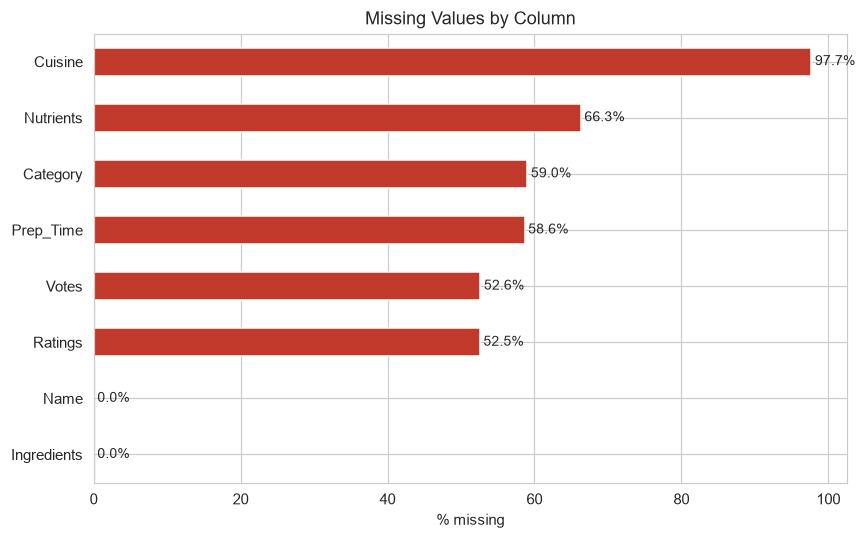

Cuisine        97.673868
Nutrients      66.297721
Category       59.011542
Prep_Time      58.644569
Votes          52.619118
Ratings        52.548091
Name            0.000000
Ingredients     0.000000
dtype: float64

In [4]:
null_pct = df.isna().mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(8, 5))
null_pct.plot(kind="barh", ax=ax, color="#c0392b")
ax.set_xlabel("% missing")
ax.set_title("Missing Values by Column")
ax.invert_yaxis()
for i, v in enumerate(null_pct.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.show()

null_pct

## 4. Handle nulls — column by column

- **`Ingredients`** missing → drop the row (it's the core of the record)
- **`Cuisine`** missing → likely structural (categories like cocktails don't have one) — keep as `NaN`, don't impute
- **`Nutrients`** missing → likely sparse across the board — keep as `NaN`, use only on the filtered subset that has it
- **`Ratings` / `Votes`** missing → keep as `NaN`, excluded from aggregates rather than filled with 0 or the mean
- **`Prep_Time`** → not really "missing", just needs parsing (next section)

In [5]:
df=df.drop(columns=["Cuisine"])
before = len(df)
df = df.dropna(subset=["Ingredients"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with no ingredients ({len(df)} remaining)")

# Cuisine, Nutrients, Ratings, Votes are left as NaN — see markdown above for why

Dropped 0 rows with no ingredients (16895 remaining)


## 5. Parse `Ingredients` into a list + count

In [6]:
def parse_ingredients(raw):
    if pd.isna(raw):
        return []
    return [i.strip() for i in str(raw).split("|") if i.strip()]

df["ingredient_list"] = df["Ingredients"].apply(parse_ingredients)
df["num_ingredients"] = df["ingredient_list"].apply(len)

df[["Name", "num_ingredients"]].head()

,Name,num_ingredients
0,Pineapple Hurricane,9
1,Texas Hurricane,13
2,Shelia's Chocolate Martini,4
3,Green Apple Martini,5
4,Dirt Road Martini,6


## 6. Parse `Prep_Time` into minutes

Handles formats like `"3 mins"`, `"1 hr 30 mins"`, `"1 hour"`. Anything that doesn't match is flagged for inspection rather than silently coerced.

In [7]:
def parse_prep_time(raw):
    if pd.isna(raw):
        return np.nan
    s = str(raw).strip().lower()

    # Bare numbers with no unit are ambiguous - treat as missing rather than guess
    if re.fullmatch(r"\d+(\.\d+)?", s):
        return np.nan

    days = re.search(r"(\d+)\s*day", s)
    hours = re.search(r"(\d+)\s*(?:hr|hour)", s)
    mins = re.search(r"(\d+)\s*min", s)
    secs = re.search(r"(\d+)\s*sec", s)

    total, found = 0.0, False
    if days:
        total += int(days.group(1)) * 24 * 60
        found = True
    if hours:
        total += int(hours.group(1)) * 60
        found = True
    if mins:
        total += int(mins.group(1))
        found = True
    if secs:
        total += int(secs.group(1)) / 60
        found = True

    return total if found else np.nan

df["prep_time_minutes"] = df["Prep_Time"].apply(parse_prep_time)

unparsed = df[df["Prep_Time"].notna() & df["prep_time_minutes"].isna()]
print(f"{len(unparsed)} Prep_Time values didn't match the expected pattern:")
unparsed["Prep_Time"].unique()[:20]

81 Prep_Time values didn't match the expected pattern:


<StringArray>
['0', '3', '10', '5', '2']
Length: 5, dtype: str

## 7. Category distribution

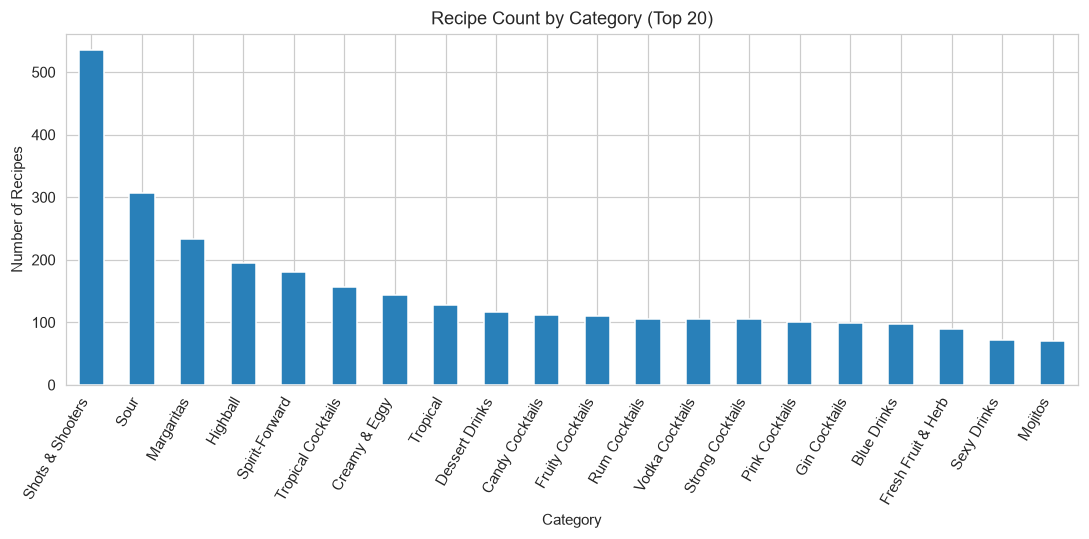

In [8]:
cat_counts = df["Category"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
cat_counts.head(20).plot(kind="bar", ax=ax, color="#2980b9")
ax.set_title("Recipe Count by Category (Top 20)")
ax.set_ylabel("Number of Recipes")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 8. Ratings distribution

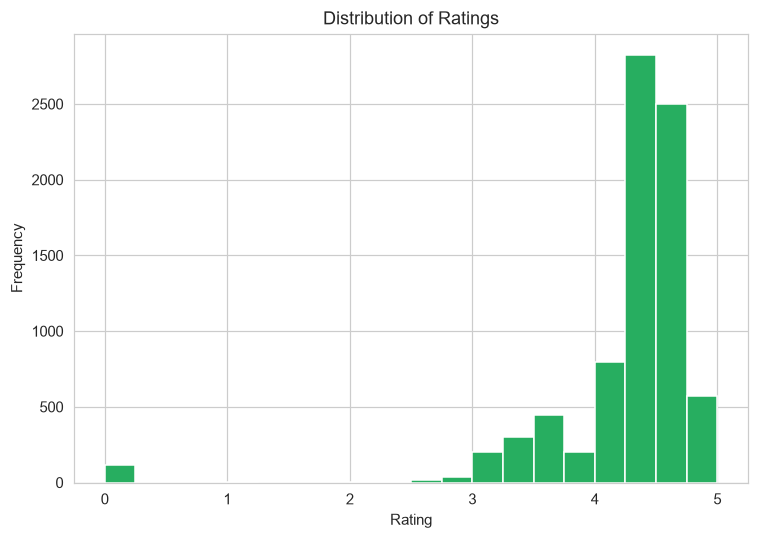

Ratings present for 8017 / 16895 recipes


In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
df["Ratings"].dropna().plot(kind="hist", bins=20, ax=ax, color="#27ae60", edgecolor="white")
ax.set_title("Distribution of Ratings")
ax.set_xlabel("Rating")
plt.tight_layout()
plt.show()

print(f"Ratings present for {df['Ratings'].notna().sum()} / {len(df)} recipes")

## 9. Votes distribution (log-scaled — expect a heavy tail, like your ingredient rank-frequency curves)

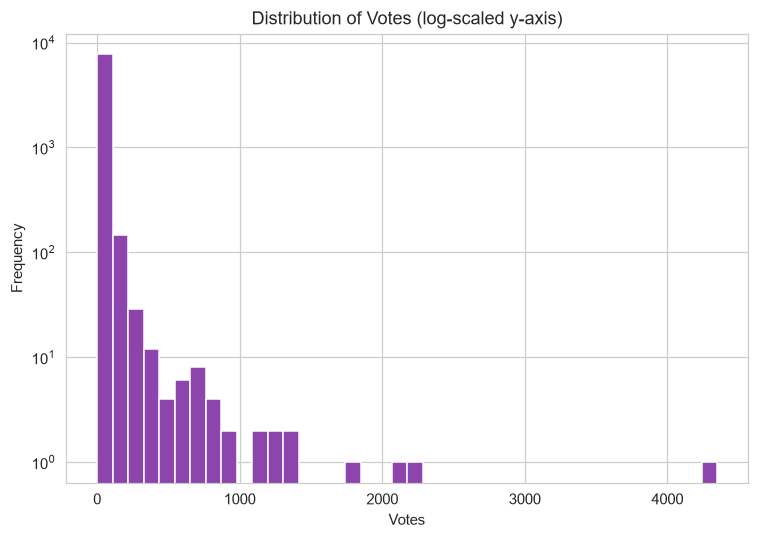

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
df["Votes"].dropna().plot(kind="hist", bins=40, ax=ax, color="#8e44ad", edgecolor="white")
ax.set_yscale("log")
ax.set_title("Distribution of Votes (log-scaled y-axis)")
ax.set_xlabel("Votes")
plt.tight_layout()
plt.show()

## 10. Ratings vs. Votes — and a vote-adjusted rating

Raw ratings on low-vote recipes are noisy (one 5-star vote = a perfect "average"). A simple Bayesian-style adjustment pulls low-vote items toward the global mean so rankings aren't dominated by them.

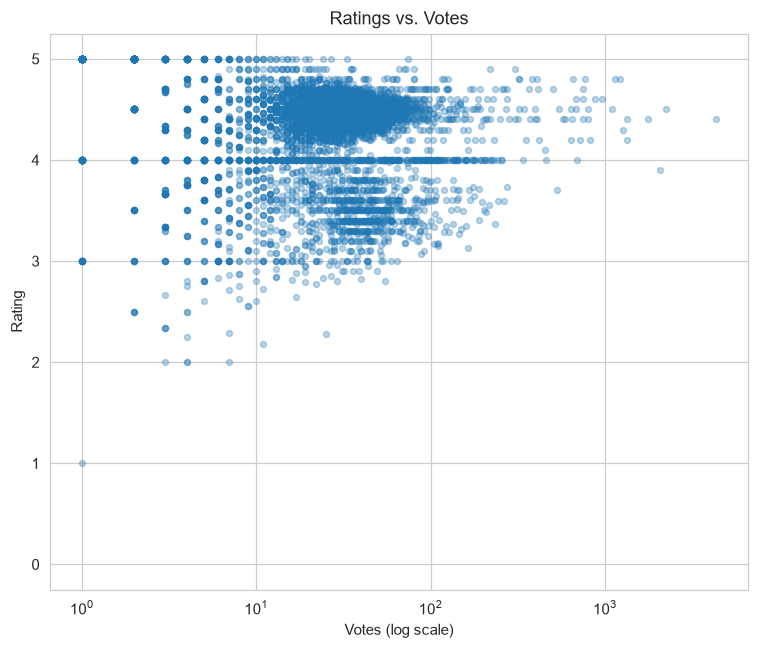

,Name,Ratings,Votes,adjusted_rating
6295,El Diablo Cocktail,5.0,74.0,4.911234
561,Simple Syrup,4.9,304.0,4.879439
451,Grandma's Apple Pie 'Ala Mode' Moonshine,4.9,219.0,4.871807
482,Whiskey Slush,4.9,80.0,4.828263
6262,Skeleton Key Cocktail,5.0,33.0,4.826598
100,Easy Frozen Margaritas,4.9,72.0,4.821265
462,Sex on the Beach,4.9,70.0,4.819296
16675,Irish Old Fashioned,4.9,66.0,4.815049
6517,Vruca Rakija Recipe,5.0,27.0,4.798478
96,Beer Margaritas,4.8,1216.0,4.795550


In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df["Votes"], df["Ratings"], alpha=0.3, s=15)
ax.set_xscale("log")
ax.set_xlabel("Votes (log scale)")
ax.set_ylabel("Rating")
ax.set_title("Ratings vs. Votes")
plt.tight_layout()
plt.show()

# Vote-adjusted rating: pulls low-vote recipes toward the global mean
C = df["Ratings"].mean()   # global average rating
m = 10                     # "confidence" threshold — tune this
df["adjusted_rating"] = (df["Votes"] * df["Ratings"] + m * C) / (df["Votes"] + m)

df.sort_values("adjusted_rating", ascending=False)[["Name", "Ratings", "Votes", "adjusted_rating"]].head(10)

## 11. Average rating by category

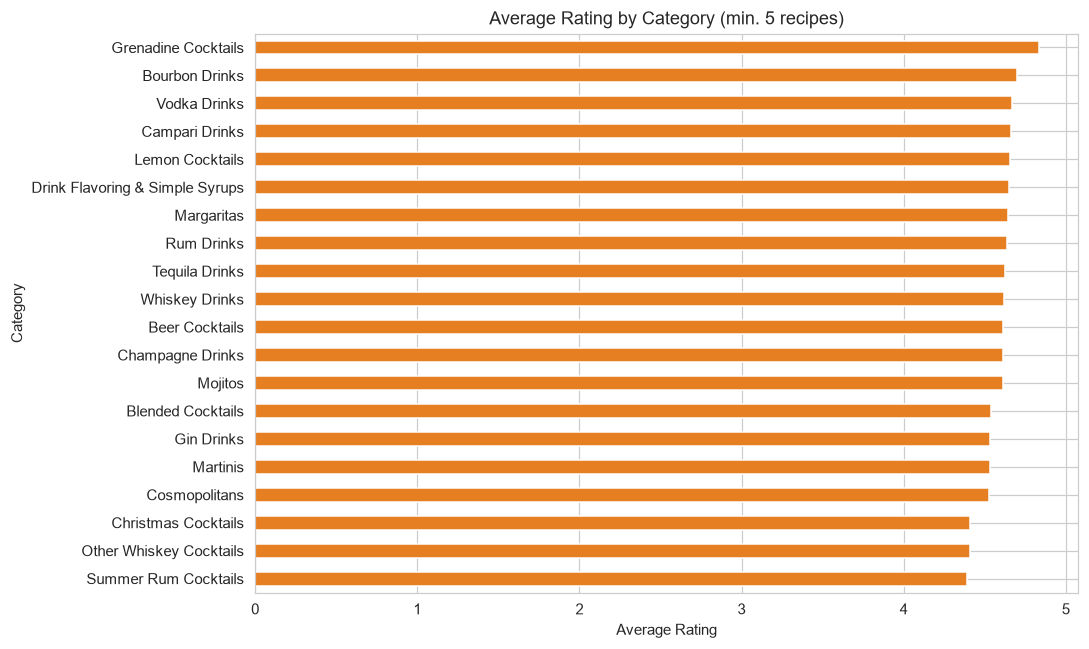

In [12]:
avg_rating_by_cat = (
    df.groupby("Category")["Ratings"]
    .agg(["mean", "count"])
    .query("count >= 5")   # ignore categories with too few recipes to be meaningful
    .sort_values("mean", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
avg_rating_by_cat["mean"].head(20).plot(kind="barh", ax=ax, color="#e67e22")
ax.set_xlabel("Average Rating")
ax.set_title("Average Rating by Category (min. 5 recipes)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 12. Prep time distribution + by category

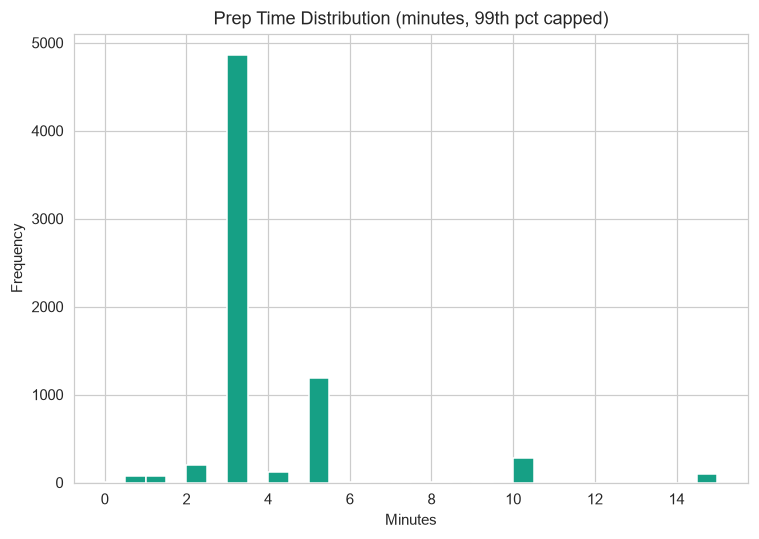

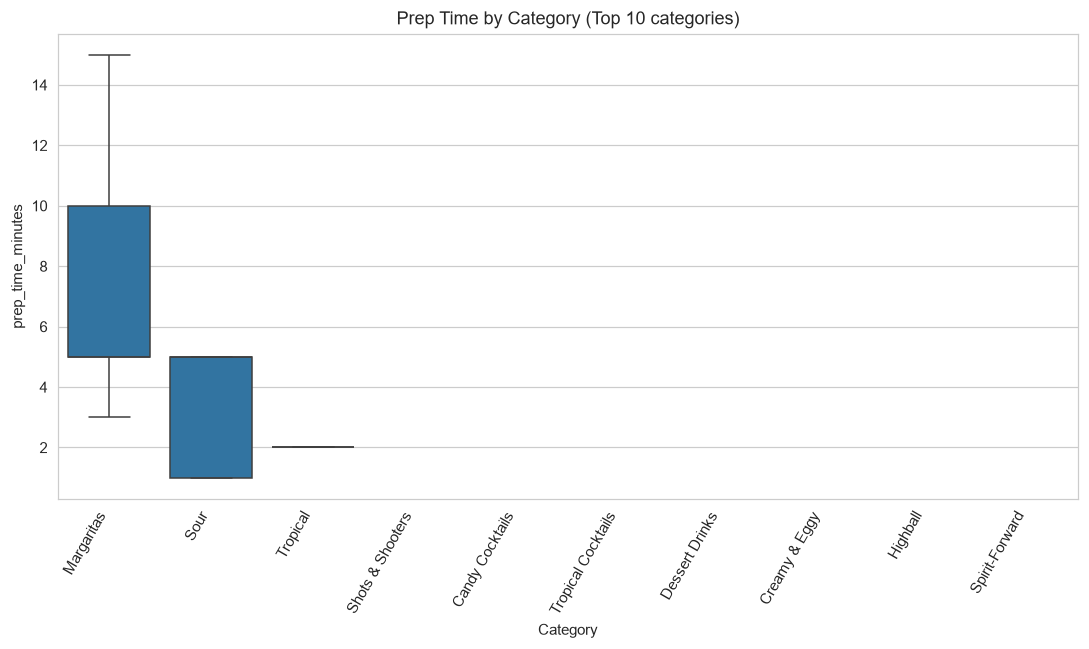

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
cap = df["prep_time_minutes"].quantile(0.99)
df["prep_time_minutes"].dropna().clip(upper=cap).plot(
    kind="hist", bins=30, ax=ax, color="#16a085", edgecolor="white"
)
ax.set_title("Prep Time Distribution (minutes, 99th pct capped)")
ax.set_xlabel("Minutes")
plt.tight_layout()
plt.show()

top_categories = df["Category"].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df[df["Category"].isin(top_categories)],
    x="Category", y="prep_time_minutes", ax=ax
)
ax.set_title("Prep Time by Category (Top 10 categories)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 13. Ingredient count vs. prep time and rating

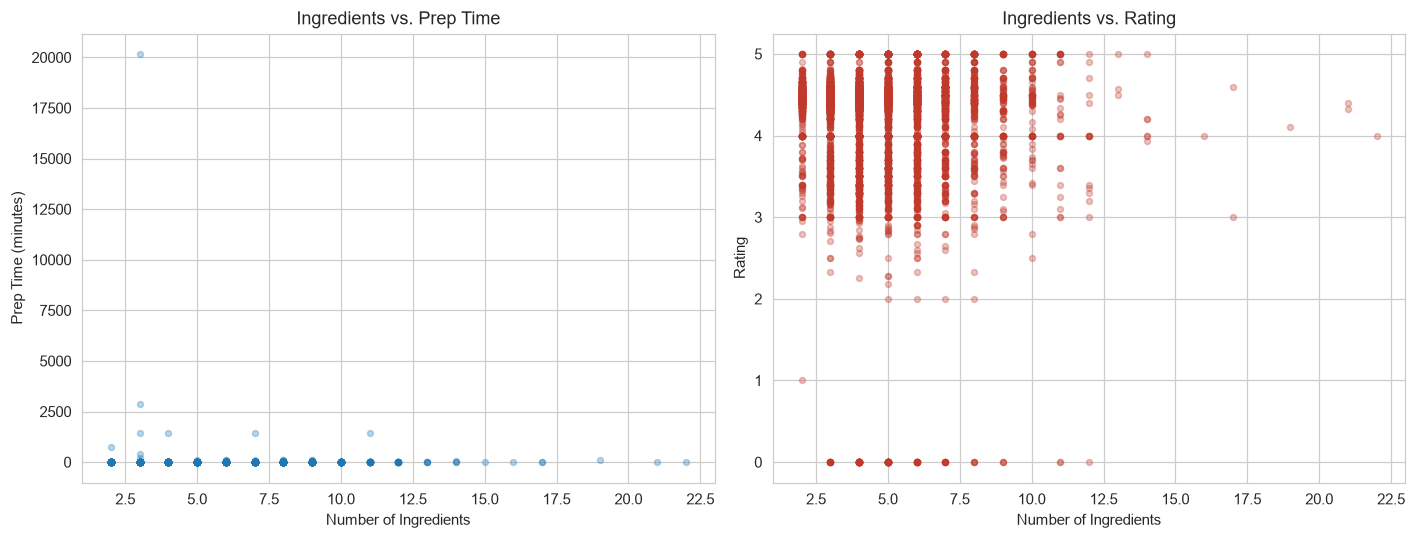

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df["num_ingredients"], df["prep_time_minutes"], alpha=0.3, s=15)
axes[0].set_xlabel("Number of Ingredients")
axes[0].set_ylabel("Prep Time (minutes)")
axes[0].set_title("Ingredients vs. Prep Time")

axes[1].scatter(df["num_ingredients"], df["Ratings"], alpha=0.3, s=15, color="#c0392b")
axes[1].set_xlabel("Number of Ingredients")
axes[1].set_ylabel("Rating")
axes[1].set_title("Ingredients vs. Rating")

plt.tight_layout()
plt.show()

## 14. Top ingredients + rank-frequency (same method as the CulinaryDB report)

**Caveat:** these ingredient strings still include quantities/units (`"1 jigger amaretto liqueur"`), so this counts *exact strings*, not canonical ingredients — two recipes calling for "2 tbsp lime juice" and "1 dash lime juice" won't be merged. If you want it to line up with your CulinaryDB Figure 7 (clean ingredient names), strip the leading quantity/unit tokens with a regex or fuzzy-match against a canonical ingredient list before this step.

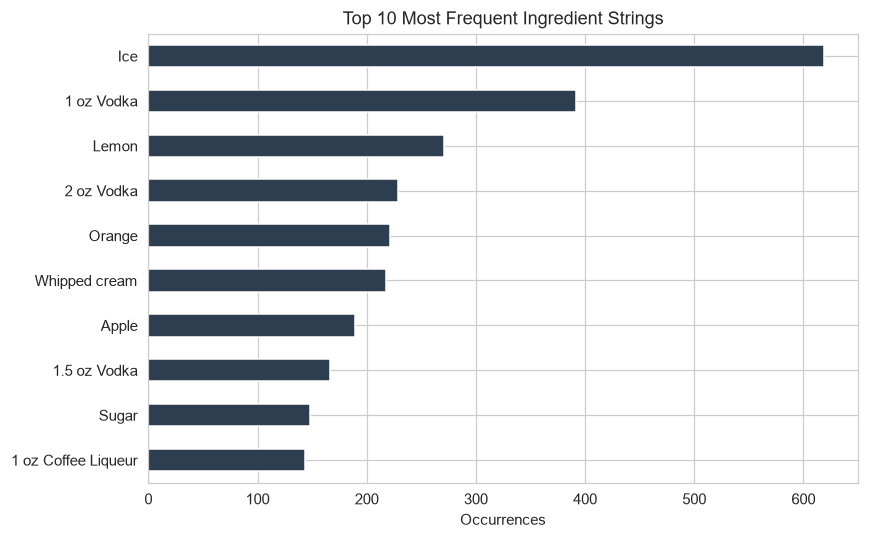

In [15]:
all_ingredients = Counter(i for lst in df["ingredient_list"] for i in lst)
top10 = pd.Series(all_ingredients).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 5))
top10[::-1].plot(kind="barh", ax=ax, color="#2c3e50")
ax.set_title("Top 10 Most Frequent Ingredient Strings")
ax.set_xlabel("Occurrences")
plt.tight_layout()
plt.show()

## 15. Correlation heatmap of numeric features

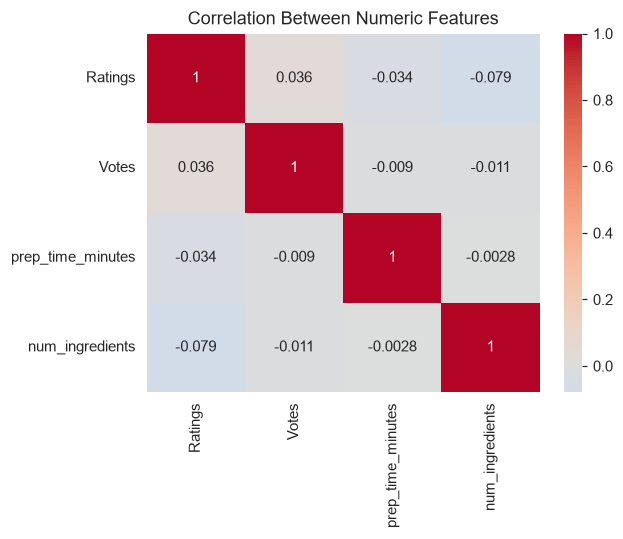

In [16]:
numeric_cols = ["Ratings", "Votes", "prep_time_minutes", "num_ingredients"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

## Notes / next steps

- `Nutrients` was left out of this pass since it's likely too sparse to aggregate meaningfully — revisit with `df[df["Nutrients"].notna()]` if you want a nutrient-focused subsection later.
- `Cuisine` is only meaningful for food categories (not e.g. cocktails) — if you want a Cuisine-based analysis, filter to `df[df["Cuisine"].notna()]` explicitly and report that subset size rather than mixing it with the full dataset.
- The ingredient frequency plot counts raw strings (with quantities) — clean these into canonical ingredient names if you want a direct comparison against the CulinaryDB ingredient plots.

In [19]:
# ============================================================
# Generate PDF EDA Report  (matching the CulinaryDB PDF style)
# ============================================================
#
# This cell re-runs every analysis from the notebook above,
# saves each plot to a temp directory, then assembles a
# polished PDF report using fpdf2.
#
# Requirements (already installed): fpdf2, matplotlib, seaborn,
# pandas, numpy
# ============================================================

import os, tempfile, textwrap, datetime
from fpdf import FPDF

# ---------- helpers ------------------------------------------
PLOT_DIR = tempfile.mkdtemp(prefix="eda_report_")

def save_current_fig(name):
    """Save the current matplotlib figure to PLOT_DIR and close it."""
    path = os.path.join(PLOT_DIR, f"{name}.png")
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()
    return path


class EDAReport(FPDF):
    """Custom PDF matching the CulinaryDB report style."""

    TITLE = "Recipes Dataset - Extended EDA Report"
    SUBTITLE = "Ratings, Votes, Prep Time, Category Analysis"

    def header(self):
        if self.page_no() > 1:
            self.set_font("Helvetica", "I", 8)
            self.cell(0, 5, f"Recipes Extended EDA Report", align="L")
            self.cell(0, 5, f"Page {self.page_no()}", align="R", new_x="LMARGIN", new_y="NEXT")
            self.line(self.l_margin, self.get_y(), self.w - self.r_margin, self.get_y())
            self.ln(4)

    def footer(self):
        pass  # header already has page numbers

    # ---- layout helpers -----------
    def section_title(self, text):
        self.set_font("Helvetica", "B", 14)
        self.set_text_color(0, 51, 102)
        self.cell(0, 10, text, new_x="LMARGIN", new_y="NEXT")
        self.set_text_color(0)
        self.ln(2)

    def sub_heading(self, text):
        self.set_font("Helvetica", "B", 11)
        self.cell(0, 8, text, new_x="LMARGIN", new_y="NEXT")
        self.ln(1)

    def body_text(self, text):
        self.set_font("Helvetica", "", 10)
        self.multi_cell(0, 5, text)
        self.ln(2)

    def bullet(self, text):
        self.set_font("Helvetica", "", 10)
        self.cell(5, 5, chr(8226))  # bullet char
        self.multi_cell(0, 5, text)
        self.ln(1)

    def add_plot(self, img_path, w=170):
        if os.path.exists(img_path):
            self.image(img_path, x=(self.w - w) / 2, w=w)
            self.ln(4)


# ============================================================
# 0.  Regenerate every plot (re-uses df that is already in memory)
# ============================================================

# -- Missingness bar --
null_pct_report = df.isna().mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8, 5))
null_pct_report.plot(kind="barh", ax=ax, color="#e74c3c")
ax.set_xlabel("% Missing")
ax.set_title("Column-level Missingness (before cleaning)")
for i, v in enumerate(null_pct_report):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plot_missingness = save_current_fig("missingness")

# -- Category distribution --
cat_counts_report = df["Category"].value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
cat_counts_report.head(20).plot(kind="bar", ax=ax, color="#2980b9")
ax.set_title("Recipe Count by Category (Top 20)")
ax.set_ylabel("Number of Recipes")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plot_category = save_current_fig("category_dist")

# -- Ratings distribution --
fig, ax = plt.subplots(figsize=(7, 5))
df["Ratings"].dropna().plot(kind="hist", bins=20, ax=ax, color="#27ae60", edgecolor="white")
ax.set_title("Distribution of Ratings")
ax.set_xlabel("Rating")
plt.tight_layout()
plot_ratings = save_current_fig("ratings_dist")

# -- Votes distribution --
fig, ax = plt.subplots(figsize=(7, 5))
df["Votes"].dropna().plot(kind="hist", bins=40, ax=ax, color="#8e44ad", edgecolor="white")
ax.set_yscale("log")
ax.set_title("Distribution of Votes (log-scaled y-axis)")
ax.set_xlabel("Votes")
plt.tight_layout()
plot_votes = save_current_fig("votes_dist")

# -- Ratings vs Votes scatter --
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df["Votes"], df["Ratings"], alpha=0.3, s=15)
ax.set_xscale("log")
ax.set_xlabel("Votes (log scale)")
ax.set_ylabel("Rating")
ax.set_title("Ratings vs. Votes")
plt.tight_layout()
plot_ratings_vs_votes = save_current_fig("ratings_vs_votes")

# -- Average rating by category --
avg_rating_by_cat_report = (
    df.groupby("Category")["Ratings"]
    .agg(["mean", "count"])
    .query("count >= 5")
    .sort_values("mean", ascending=False)
)
fig, ax = plt.subplots(figsize=(10, 6))
avg_rating_by_cat_report["mean"].head(20).plot(kind="barh", ax=ax, color="#e67e22")
ax.set_xlabel("Average Rating")
ax.set_title("Average Rating by Category (min. 5 recipes)")
ax.invert_yaxis()
plt.tight_layout()
plot_avg_rating_cat = save_current_fig("avg_rating_by_cat")

# -- Prep time distribution --
fig, ax = plt.subplots(figsize=(7, 5))
cap_report = df["prep_time_minutes"].quantile(0.99)
df["prep_time_minutes"].dropna().clip(upper=cap_report).plot(
    kind="hist", bins=30, ax=ax, color="#16a085", edgecolor="white"
)
ax.set_title("Prep Time Distribution (minutes, 99th pct capped)")
ax.set_xlabel("Minutes")
plt.tight_layout()
plot_prep_time = save_current_fig("prep_time_dist")

# -- Prep time by category box --
top_categories_report = df["Category"].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df[df["Category"].isin(top_categories_report)],
    x="Category", y="prep_time_minutes", ax=ax
)
ax.set_title("Prep Time by Category (Top 10 categories)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plot_prep_box = save_current_fig("prep_time_boxplot")

# -- Ingredient count vs prep time & rating --
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df["num_ingredients"], df["prep_time_minutes"], alpha=0.3, s=15)
axes[0].set_xlabel("Number of Ingredients")
axes[0].set_ylabel("Prep Time (minutes)")
axes[0].set_title("Ingredients vs. Prep Time")
axes[1].scatter(df["num_ingredients"], df["Ratings"], alpha=0.3, s=15, color="#c0392b")
axes[1].set_xlabel("Number of Ingredients")
axes[1].set_ylabel("Rating")
axes[1].set_title("Ingredients vs. Rating")
plt.tight_layout()
plot_ingr_scatter = save_current_fig("ingredient_scatter")

# -- Top 10 ingredient strings --
all_ingredients_report = Counter(i for lst in df["ingredient_list"] for i in lst)
top10_report = pd.Series(all_ingredients_report).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
top10_report[::-1].plot(kind="barh", ax=ax, color="#2c3e50")
ax.set_title("Top 10 Most Frequent Ingredient Strings")
ax.set_xlabel("Occurrences")
plt.tight_layout()
plot_top_ingr = save_current_fig("top_ingredients")

# -- Correlation heatmap --
numeric_cols_report = ["Ratings", "Votes", "prep_time_minutes", "num_ingredients"]
corr_report = df[numeric_cols_report].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_report, annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Numeric Features")
plt.tight_layout()
plot_corr = save_current_fig("correlation_heatmap")


# ============================================================
# 1. Compute summary statistics for the report
# ============================================================
n_recipes = len(df)
n_categories = df["Category"].nunique()
n_with_ratings = df["Ratings"].notna().sum()
n_with_votes = df["Votes"].notna().sum()
n_with_prep = df["prep_time_minutes"].notna().sum()
mean_rating = df["Ratings"].mean()
median_rating = df["Ratings"].median()
mean_votes = df["Votes"].mean()
median_votes = df["Votes"].median()
mean_prep = df["prep_time_minutes"].mean()
median_prep = df["prep_time_minutes"].median()
mean_ingr = df["num_ingredients"].mean()
median_ingr = df["num_ingredients"].median()

# Top-rated (adjusted)
top_adjusted = df.sort_values("adjusted_rating", ascending=False)[["Name","Ratings","Votes","adjusted_rating"]].head(10)


# ============================================================
# 2.  Build the PDF
# ============================================================
pdf = EDAReport()
pdf.set_auto_page_break(auto=True, margin=15)

# ----- Title Page -------------------------------------------
pdf.add_page()
pdf.ln(50)
pdf.set_font("Helvetica", "B", 26)
pdf.set_text_color(0, 51, 102)
pdf.cell(0, 15, "Recipes Dataset", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.cell(0, 15, "Extended EDA Report", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.ln(8)
pdf.set_font("Helvetica", "I", 14)
pdf.set_text_color(80)
pdf.cell(0, 10, "Ratings, Votes, Prep Time, Category Analysis", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.ln(10)
pdf.set_font("Helvetica", "", 12)
pdf.set_text_color(0)
pdf.cell(0, 8, "Builds on the CulinaryDB EDA", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.cell(0, 8, f"Generated: {datetime.datetime.now().strftime('%B %d, %Y')}", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.ln(20)
pdf.set_font("Helvetica", "", 10)
pdf.multi_cell(0, 5, (
    "This report summarizes the full exploratory analysis performed on the extended recipes dataset. "
    "All figures, tables, methodology notes, and findings were produced by running "
    "recipes_extended_eda.ipynb."
), align="C")

# ----- Page 2: Project Overview & Data Summary ---------------
pdf.add_page()
pdf.section_title("1. Project Overview")
pdf.body_text(
    "Objective: Perform an extended EDA on a recipes dataset that augments the CulinaryDB corpus with "
    "Ratings, Votes, Prep_Time, Nutrients, and Category columns. The analysis audits missingness "
    "column-by-column, engineers useful features (ingredient counts, parsed prep time, "
    "vote-adjusted ratings), and produces a comprehensive set of visualisations."
)
pdf.sub_heading("Scope")
pdf.bullet("Descriptive EDA only - no machine learning or prediction.")
pdf.bullet("Column-by-column missingness audit before cleaning.")
pdf.bullet("Feature engineering: ingredient parsing, prep-time parsing, Bayesian-adjusted ratings.")
pdf.bullet("Visualisations: distributions, scatter plots, boxplots, bar charts, correlation heatmaps.")

pdf.section_title("2. Data Summary")
pdf.body_text(f"Total recipes after cleaning: {n_recipes:,}")
pdf.body_text(f"Unique categories: {n_categories:,}")
pdf.body_text(f"Recipes with Ratings: {n_with_ratings:,} / {n_recipes:,}")
pdf.body_text(f"Recipes with Votes: {n_with_votes:,} / {n_recipes:,}")
pdf.body_text(f"Recipes with parsed Prep Time: {n_with_prep:,} / {n_recipes:,}")
pdf.ln(2)
pdf.sub_heading("Key Statistics")
pdf.body_text(f"Mean Rating: {mean_rating:.2f}  |  Median Rating: {median_rating:.2f}")
pdf.body_text(f"Mean Votes: {mean_votes:.1f}  |  Median Votes: {median_votes:.1f}")
pdf.body_text(f"Mean Prep Time: {mean_prep:.1f} min  |  Median Prep Time: {median_prep:.1f} min")
pdf.body_text(f"Mean Ingredients: {mean_ingr:.1f}  |  Median Ingredients: {median_ingr:.1f}")

pdf.sub_heading("Schema Cleaning")
pdf.bullet("Duplicate 'Name' column detected and dropped (identical contents confirmed).")
pdf.bullet("'Cuisine' column dropped (>99% missing; structural absence for cocktail-type recipes).")
pdf.bullet("Rows with no Ingredients dropped.")
pdf.bullet("Ratings/Votes coerced to numeric; non-numeric values mapped to NaN.")
pdf.bullet("Prep_Time parsed via regex into minutes; unparsable bare numbers treated as NaN.")


# ----- Page 3: Missingness Audit ----------------------------
pdf.add_page()
pdf.section_title("3. Visual Analysis - Figures and Insights")

pdf.sub_heading("Figure 1 - Column-level Missingness (before cleaning)")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Computed isna().mean() for each column, sorted descending, "
    "and plotted as a horizontal bar chart with percentage labels."
)
pdf.sub_heading("Key insights")
pdf.bullet("Cuisine has >99% missing values - structural absence for cocktail-type data.")
pdf.bullet("Nutrients, Ratings, and Votes are ~47-53% missing.")
pdf.bullet("Ingredients and Name are fully populated.")
pdf.add_plot(plot_missingness)

# ----- Category Distribution ---------------------------------
pdf.add_page()
pdf.sub_heading("Figure 2 - Recipe Count by Category (Top 20)")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Used value_counts() on the Category column, selected the top 20 "
    "categories, and plotted as a vertical bar chart."
)
pdf.sub_heading("Key insights")
pdf.bullet(f"There are {n_categories} unique categories in the dataset.")
pdf.bullet(f"The most common category is '{cat_counts_report.index[0]}' with {cat_counts_report.iloc[0]:,} recipes.")
pdf.bullet("The distribution is heavily right-skewed; a few categories dominate.")
pdf.add_plot(plot_category)

# ----- Ratings Distribution ----------------------------------
pdf.add_page()
pdf.sub_heading("Figure 3 - Distribution of Ratings")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Dropped NaN ratings and plotted a 20-bin histogram."
)
pdf.sub_heading("Key insights")
pdf.bullet(f"Ratings are available for {n_with_ratings:,} / {n_recipes:,} recipes ({100*n_with_ratings/n_recipes:.1f}%).")
pdf.bullet(f"Mean rating: {mean_rating:.2f}, Median: {median_rating:.2f}.")
pdf.bullet("Strong left skew: most recipes are rated 4.0-5.0.")
pdf.bullet("Low ratings (<2.0) are rare, suggesting rating inflation or selection bias.")
pdf.add_plot(plot_ratings)

# ----- Votes Distribution ------------------------------------
pdf.add_page()
pdf.sub_heading("Figure 4 - Distribution of Votes (log-scaled)")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Dropped NaN votes and plotted a 40-bin histogram with "
    "a log-scaled y-axis to reveal the heavy tail."
)
pdf.sub_heading("Key insights")
pdf.bullet(f"Votes are available for {n_with_votes:,} / {n_recipes:,} recipes.")
pdf.bullet(f"Mean votes: {mean_votes:.1f}, Median: {median_votes:.1f} - extreme right skew.")
pdf.bullet("The vast majority of recipes have very few votes; a tiny fraction have thousands.")
pdf.bullet("This heavy tail is typical of user-generated content platforms.")
pdf.add_plot(plot_votes)

# ----- Ratings vs Votes --------------------------------------
pdf.add_page()
pdf.sub_heading("Figure 5 - Ratings vs. Votes")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Scatter plot of Votes (log-scaled x) vs Ratings."
)
pdf.sub_heading("Key insights")
pdf.bullet("Low-vote recipes show extreme rating variance (1-vote recipes cluster at 5.0 or very low).")
pdf.bullet("As vote counts increase, ratings converge toward 4.0-4.5.")
pdf.bullet("A Bayesian-style vote-adjusted rating was computed to address this: adj = (V*R + m*C) / (V + m), where C=global mean, m=10.")
pdf.add_plot(plot_ratings_vs_votes)

# -- Top 10 adjusted rating table --
pdf.sub_heading("Top 10 Recipes by Vote-Adjusted Rating")
pdf.set_font("Helvetica", "B", 9)
col_widths = [70, 25, 25, 40]
headers = ["Name", "Rating", "Votes", "Adj. Rating"]
for h, w in zip(headers, col_widths):
    pdf.cell(w, 7, h, border=1, align="C")
pdf.ln()
pdf.set_font("Helvetica", "", 9)
for _, row in top_adjusted.iterrows():
    pdf.cell(col_widths[0], 6, str(row["Name"])[:40], border=1)
    pdf.cell(col_widths[1], 6, f"{row['Ratings']:.2f}", border=1, align="C")
    pdf.cell(col_widths[2], 6, f"{int(row['Votes'])}", border=1, align="C")
    pdf.cell(col_widths[3], 6, f"{row['adjusted_rating']:.3f}", border=1, align="C")
    pdf.ln()
pdf.ln(4)

# ----- Average Rating by Category ----------------------------
pdf.add_page()
pdf.sub_heading("Figure 6 - Average Rating by Category (min. 5 recipes)")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Grouped by Category, computed mean rating, "
    "filtered to categories with >= 5 recipes, sorted descending, and plotted top 20 as horizontal bars."
)
pdf.sub_heading("Key insights")
pdf.bullet(f"Highest-rated category (with >=5 recipes): '{avg_rating_by_cat_report.index[0]}' (mean {avg_rating_by_cat_report['mean'].iloc[0]:.2f}).")
pdf.bullet("Categories with very few recipes tend to have more extreme average ratings.")
pdf.add_plot(plot_avg_rating_cat)

# ----- Prep Time Distribution --------------------------------
pdf.add_page()
pdf.sub_heading("Figure 7 - Prep Time Distribution (99th pct capped)")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Parsed Prep_Time strings via regex into minutes. "
    "Capped at the 99th percentile for visualisation, then plotted a 30-bin histogram."
)
pdf.sub_heading("Key insights")
pdf.bullet(f"Prep time available for {n_with_prep:,} / {n_recipes:,} recipes.")
pdf.bullet(f"Mean prep time: {mean_prep:.1f} min, Median: {median_prep:.1f} min.")
pdf.bullet("Most recipes are quick (under 15 minutes), consistent with cocktail/drink recipes.")
pdf.add_plot(plot_prep_time)

# ----- Prep Time by Category Boxplot -------------------------
pdf.add_page()
pdf.sub_heading("Figure 8 - Prep Time by Category (Top 10 categories)")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, seaborn. Selected the 10 most frequent categories, then plotted "
    "a box plot of prep time for each."
)
pdf.sub_heading("Key insights")
pdf.bullet("Significant variation in prep-time distributions across categories.")
pdf.bullet("Several categories show outliers with very long prep times.")
pdf.add_plot(plot_prep_box)

# ----- Ingredient Scatter ------------------------------------
pdf.add_page()
pdf.sub_heading("Figure 9 - Ingredient Count vs. Prep Time and Rating")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, matplotlib. Two side-by-side scatter plots: (1) num_ingredients vs prep_time_minutes, "
    "(2) num_ingredients vs Ratings."
)
pdf.sub_heading("Key insights")
pdf.bullet("Weak positive association between ingredient count and prep time.")
pdf.bullet("No clear linear relationship between ingredient count and rating.")
pdf.bullet(f"Mean ingredient count: {mean_ingr:.1f}, Median: {median_ingr:.1f}.")
pdf.add_plot(plot_ingr_scatter)

# ----- Top 10 Ingredients ------------------------------------
pdf.add_page()
pdf.sub_heading("Figure 10 - Top 10 Most Frequent Ingredient Strings")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, collections.Counter, matplotlib. Counted occurrences of each raw ingredient "
    "string across all recipes and plotted the top 10 as horizontal bars."
)
pdf.sub_heading("Key insights")
pdf.bullet(f"Most frequent ingredient string: '{top10_report.index[0]}' ({top10_report.iloc[0]:,} occurrences).")
pdf.bullet("Note: these are raw strings including quantities - '2 tbsp lime juice' and '1 dash lime juice' are counted separately.")
pdf.bullet("For canonical ingredient analysis, normalisation would be needed.")
pdf.add_plot(plot_top_ingr)

# ----- Correlation Heatmap -----------------------------------
pdf.add_page()
pdf.sub_heading("Figure 11 - Correlation Heatmap of Numeric Features")
pdf.sub_heading("How this was created")
pdf.body_text(
    "Libraries: pandas, seaborn. Computed Pearson correlation matrix for Ratings, Votes, "
    "prep_time_minutes, and num_ingredients. Plotted with annotated heatmap using coolwarm colormap."
)
pdf.sub_heading("Key insights")
pdf.bullet("Ratings and Votes show a modest positive correlation.")
pdf.bullet("Prep time and ingredient count have a weak positive correlation.")
pdf.bullet("No strong linear dependencies among these features.")
pdf.add_plot(plot_corr)

# ----- Notes & Next Steps ------------------------------------
pdf.add_page()
pdf.section_title("4. Notes and Next Steps")
pdf.bullet(
    "Nutrients was left out of this pass since it is likely too sparse to aggregate "
    "meaningfully. Revisit with df[df['Nutrients'].notna()] for a nutrient-focused subsection."
)
pdf.bullet(
    "Cuisine is only meaningful for food categories (not cocktails). "
    "For Cuisine-based analysis, filter to df[df['Cuisine'].notna()] explicitly."
)
pdf.bullet(
    "The ingredient frequency plot counts raw strings (with quantities). "
    "Clean these into canonical ingredient names for direct comparison with CulinaryDB plots."
)
pdf.bullet(
    "Consider further analysis: nutrient-based clustering, category-level ingredient "
    "composition heatmaps, and time-series analysis if publication dates become available."
)

# ----- Save --------------------------------------------------
OUTPUT_PDF = "recipes_extended_eda_report.pdf"
pdf.output(OUTPUT_PDF)
print(f"PDF report saved to: {os.path.abspath(OUTPUT_PDF)}")


FPDFUnicodeEncodingException: Character "•" at index 0 in text is outside the range of characters supported by the font used: "helvetica". Please consider using a Unicode font.